# ¿Cuánto aviso nos da un río? · 03 — Comparación de estaciones y selección del modelo

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas).

**Lugar en el estudio:** este cuaderno cierra la pregunta **P1**: compara los modelos base (solo caudal local y calendario) entre las dos estaciones y aplica la regla de selección. Las etapas con más información (estaciones aguas arriba, lluvia, Chronos-2) se comparan en los cuadernos 08 y 09.

**Sobre el periodo de prueba:** la regla de selección se fijó antes de la evaluación final y elige con la validación, pero el periodo de prueba (2016–fin) se consultó durante el desarrollo del proyecto, al decidir qué modelos conservar. Las cifras de prueba se leen como la evaluación de un protocolo congelado, no como una confirmación independiente.

---

## 0. Objetivo
Reúne los resultados de `01_Modelos_Racarumi.ipynb` y `02_Modelos_Tamshiyacu.ipynb` para:
1. **Comparar seis modelos** (regresión lineal, Random Forest, XGBoost, KNN, MLP y LSTM) y el combinado por horizonte con el mismo protocolo, frente a persistencia y climatología (sección 3.6), y aplicar la **regla de selección** fijada de antemano.
2. **Comparar el horizonte útil** de las dos estaciones (hipótesis **H3**, enunciada como HP1 en los cuadernos del diagnóstico) sobre la **intersección explícita de fechas de emisión** de ambas, con un bootstrap **pareado** (las mismas réplicas de meses para las dos estaciones).
3. **Evaluar cómo cae el desempeño** con el horizonte y durante caudales elevados (**H4**, que incluye la HP3 del diagnóstico). La HP2 (la LSTM no supera de forma demostrada a los modelos clásicos a 1–3 días) se responde con la regla de selección y la comparación por familias (secciones 2 y 2.1).
4. **Revisar la estabilidad** con varios orígenes (selección interna en cada uno) y la sensibilidad a la historia y al calendario.

> **Pregunta principal:** ¿cuál es el horizonte útil del pronóstico diario de caudal en cada estación y cómo varía entre modelos, periodos y condiciones de caudal?

Los resultados se refieren a estas dos estaciones, este periodo y este experimento; dos estaciones no permiten generalizar a todas las cuencas de cada vertiente. La anticipación de **nuevas** superaciones del P95 se evalúa en `04_Anticipacion_Crecidas.ipynb`.

---
## 1. Configuración y lectura de resultados

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import comun as C

%matplotlib inline
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
RUTA_FIG, RUTA_TAB = C.ruta_salidas() / 'comparacion' / 'figuras', C.ruta_salidas() / 'comparacion' / 'tablas'          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

EST = ['Racarumi', 'Tamshiyacu']
COL_EST = {'Racarumi': '#d95f02', 'Tamshiyacu': '#1b9e77'}
R, T, Z = {}, {}, {}
for e in EST:
    base = C.ruta_salidas() / e.lower()
    tb = base / 'tablas'
    R[e] = json.loads((base / 'resumen.json').read_text(encoding='utf-8'))
    C.verificar_resumen(base / 'resumen.json')        # mismo protocolo y mismo modo de ejecución (final o rápido)
    T[e] = {k: pd.read_csv(tb / f'{k}.csv') for k in ['tabla_metricas_prueba', 'tabla_metricas_prueba_comun', 'tabla_crecidas_prueba',
                                                      'tabla_crecidas_prueba_comun', 'tabla_memoria', 'tabla_eventos_pronostico',
                                                      'tabla_estabilidad_temporal', 'tabla_semillas']}
    for k in ['tabla_horizonte_util', 'tabla_horizonte_util_comun', 'tabla_referencias_prueba', 'tabla_referencias_prueba_comun',
              'tabla_importancia', 'tabla_eventos_resumen', 'tabla_presupuesto_busqueda', 'tabla_seleccion']:
        T[e][k] = pd.read_csv(tb / f'{k}.csv', index_col=0)
    Z[e] = np.load(base / 'predicciones.npz', allow_pickle=False)
    print(f"{e:11s} periodo {R[e]['periodo']} | seleccionado: {R[e]['mejor_modelo']} (mayor NSE: {R[e]['mayor_nse']}) | P95 = {R[e]['P95']:,.1f} m³/s | "
          f"fechas comunes: {R[e]['fechas_comunes']}")
MODELOS = C.MODELOS

Racarumi    periodo 1981-01-01 a 2023-08-31 | seleccionado: LSTM (mayor NSE: LSTM) | P95 = 111.2 m³/s | fechas comunes: {'n': 2373, 'inicio': '2016-01-01', 'fin': '2023-03-31'}
Tamshiyacu  periodo 1984-09-01 a 2025-12-31 | seleccionado: XGBoost (mayor NSE: XGBoost) | P95 = 47,602.8 m³/s | fechas comunes: {'n': 2373, 'inicio': '2016-01-01', 'fin': '2023-03-31'}


---
## 2. Tabla comparativa de los seis modelos (sección 3.6)
La tabla reúne (a) la **regla de selección** de cada estación (bloque de selección 2012–2015, con la corrección de retransformación estimada en 2009–2011): diferencia pareada con el mejor, IC 90 % y clase; y (b) junto al criterio de selección, las métricas de prueba en las **fechas comunes**, el horizonte útil y su incertidumbre. El combinado por horizonte se muestra aparte (no compite en la selección).

In [2]:
selec = pd.concat({e: T[e]['tabla_seleccion'] for e in EST}, names=['estación', 'modelo'])
selec.to_csv(RUTA_TAB / 'tabla_seleccion_comparada.csv')
display(selec.round(4))
filas = []
for e in EST:
    hc, hf = T[e]['tabla_horizonte_util_comun'], T[e]['tabla_horizonte_util']
    mc = T[e]['tabla_metricas_prueba_comun'].set_index(['modelo', 'h'])
    cr = T[e]['tabla_crecidas_prueba_comun'].set_index(['modelo', 'h'])
    for n in hc.index:
        filas.append({'estación': e, 'modelo': n, 'NSE medio selección': hf.loc[n, 'NSE medio selección'],
                      **{f'NSE h={h}': hc.loc[n, f'NSE h={h}'] for h in (1, 7, 30)},
                      'MAE h=7 (m³/s)': mc.loc[(n, 7), 'MAE'], 'KGE h=7': mc.loc[(n, 7), 'KGE'], 'PBIAS h=7 (%)': mc.loc[(n, 7), 'PBIAS'],
                      'H cota 95 % (d)': hc.loc[n, 'H cota 95 % (d)'], 'H puntual (d)': hc.loc[n, 'H puntual (d)'],
                      'H p05–p95 (d)': f"{int(hc.loc[n, 'H p05 (d)'])}–{int(hc.loc[n, 'H p95 (d)'])}",
                      'NSE ≥ 0.5 hasta (d)': hc.loc[n, 'NSE ≥ 0.5 hasta (d)'],
                      'H cota, prueba completa (d)': hf.loc[n, 'H cota 95 % (d)'], 'CSI diario h=3': cr.loc[(n, 3), 'CSI']})
comp = pd.DataFrame(filas).set_index(['estación', 'modelo'])
comp.to_csv(RUTA_TAB / 'tabla_comparativa_modelos.csv')
comp.round(3)

NSE medio selección  diferencia con el mejor  \
estación   modelo                                                           
Racarumi   LSTM                           0.5599                   0.0000   
           Regresión lineal               0.5531                  -0.0067   
           MLP                            0.5458                  -0.0141   
           Random Forest                  0.5365                  -0.0234   
           KNN                            0.5323                  -0.0276   
           XGBoost                        0.5321                  -0.0278   
Tamshiyacu XGBoost                        0.9354                   0.0000   
           Random Forest                  0.9316                  -0.0038   
           KNN                            0.9304                  -0.0051   
           MLP                            0.9286                  -0.0068   
           LSTM                           0.9237                  -0.0117   
           Regresión lineal               0.9027                  -0.0327   

                             IC90 inferior  IC90 superior       clase  \
estación   modelo                                                       
Racarumi   LSTM                        NaN            NaN       mejor   
           Regresión lineal        -0.0387         0.0251  inconcluso   
           MLP                     -0.0445         0.0148  inconcluso   
           Random Forest           -0.0597         0.0098  inconcluso   
           KNN                     -0.0627         0.0005  inconcluso   
           XGBoost                 -0.0514        -0.0033        peor   
Tamshiyacu XGBoost                     NaN            NaN       mejor   
           Random Forest           -0.0123         0.0024  inconcluso   
           KNN                     -0.0148         0.0024  inconcluso   
           MLP                     -0.0147        -0.0001        peor   
           LSTM                    -0.0216        -0.0027        peor   
           Regresión lineal        -0.0573        -0.0130        peor   

                             seleccionado  
estación   modelo                          
Racarumi   LSTM                      True  
           Regresión lineal         False  
           MLP                      False  
           Random Forest            False  
           KNN                      False  
           XGBoost                  False  
Tamshiyacu XGBoost                   True  
           Random Forest            False  
           KNN                      False  
           MLP                      False  
           LSTM                     False  
           Regresión lineal         False

NSE medio selección  NSE h=1  NSE h=7  \
estación   modelo                                                           
Racarumi   Regresión lineal                       0.553    0.846    0.479   
           Random Forest                          0.537    0.854    0.517   
           XGBoost                                0.532    0.858    0.503   
           KNN                                    0.532    0.846    0.443   
           MLP                                    0.546    0.857    0.512   
           LSTM                                   0.560    0.850    0.503   
           Combinado por horizonte                  NaN    0.858    0.503   
Tamshiyacu Regresión lineal                       0.903    0.999    0.963   
           Random Forest                          0.932    0.999    0.967   
           XGBoost                                0.935    0.999    0.967   
           KNN                                    0.930    0.999    0.967   
           MLP                                    0.929    0.999    0.966   
           LSTM                                   0.924    0.999    0.964   
           Combinado por horizonte                  NaN    0.999    0.967   

                                    NSE h=30  MAE h=7 (m³/s)  KGE h=7  \
estación   modelo                                                       
Racarumi   Regresión lineal            0.445          16.962    0.628   
           Random Forest               0.445          16.340    0.638   
           XGBoost                     0.448          16.530    0.644   
           KNN                         0.417          17.247    0.651   
           MLP                         0.468          16.454    0.634   
           LSTM                        0.466          16.451    0.653   
           Combinado por horizonte     0.445          16.451    0.653   
Tamshiyacu Regresión lineal            0.770        1620.005    0.974   
           Random Forest               0.804        1522.175    0.976   
           XGBoost                     0.820        1533.365    0.975   
           KNN                         0.809        1523.443    0.978   
           MLP                         0.809        1566.348    0.967   
           LSTM                        0.834        1599.273    0.965   
           Combinado por horizonte     0.820        1533.365    0.975   

                                    PBIAS h=7 (%)  H cota 95 % (d)  \
estación   modelo                                                    
Racarumi   Regresión lineal                 0.979                5   
           Random Forest                   -1.006                6   
           XGBoost                          0.725                6   
           KNN                              3.114                4   
           MLP                             -0.641                6   
           LSTM                             0.377                6   
           Combinado por horizonte          0.377                6   
Tamshiyacu Regresión lineal                 1.021               17   
           Random Forest                    0.349               21   
           XGBoost                          0.211               22   
           KNN                              0.244               20   
           MLP                             -0.358               21   
           LSTM                            -0.157               27   
           Combinado por horizonte          0.211               22   

                                    H puntual (d) H p05–p95 (d)  \
estación   modelo                                                 
Racarumi   Regresión lineal                     8          5–19   
           Random Forest                       11          6–28   
           XGBoost                              8          6–19   
           KNN                                  6          4–13   
           MLP                                 14          6–30   
           LSTM                             

**Interpretación:**
- **Modelo seleccionado por la regla** (bloque de selección 2012–2015): **LSTM** en Racarumi (0.560; regresión lineal, MLP, Random Forest y KNN inconclusos, XGBoost peor) y **XGBoost** en Tamshiyacu (0.935; Random Forest y KNN inconclusos, MLP, LSTM y regresión lineal peores). Ninguna estación tiene un candidato demostrado equivalente al mejor.
- **Entre modelos las diferencias de NSE son pequeñas** en las fechas comunes: a 7 días, 0.443–0.517 en Racarumi y 0.963–0.967 en Tamshiyacu.
- **El horizonte útil sí separa a los modelos en Tamshiyacu:** H cota 95 % de 27 días con la LSTM, 20–22 con XGBoost, Random Forest, KNN y MLP, y 17 con la regresión lineal. En Racarumi todos quedan en 4–6 días.
- **Entre estaciones las diferencias son de otro orden:** NSE a 7 días ≈ 0.5 frente a ≈ 0.97 y H cota 4–6 frente a 17–27 días. En estas dos estaciones, **el río pesa más que el modelo** en el horizonte útil.

### 2.1 Qué aporta cada familia de modelos
Pares de modelos que responden preguntas concretas: no linealidad (regresión lineal frente a XGBoost), analogías históricas frente a un modelo lineal (KNN frente a regresión lineal), bagging frente a boosting (Random Forest frente a XGBoost) y recurrencia (MLP frente a LSTM). La tabla es descriptiva (prueba en fechas comunes); la comparación formal con incertidumbre es la de la regla de selección. El margen de importancia práctica es ±0.01 de NSE medio.

In [3]:
pares = [('Regresión lineal', 'XGBoost'), ('Regresión lineal', 'KNN'), ('Random Forest', 'XGBoost'), ('MLP', 'LSTM')]
filas = []
for e in EST:
    mc = T[e]['tabla_metricas_prueba_comun'].set_index(['modelo', 'h'])
    hc = T[e]['tabla_horizonte_util_comun']
    for a, b in pares:
        filas.append({'estación': e, 'comparación': f'{b} − {a}',
                      'Δ NSE medio selección': T[e]['tabla_horizonte_util'].loc[b, 'NSE medio selección'] - T[e]['tabla_horizonte_util'].loc[a, 'NSE medio selección'],
                      **{f'Δ NSE h={h}': mc.loc[(b, h), 'NSE'] - mc.loc[(a, h), 'NSE'] for h in (1, 7, 30)},
                      'Δ H puntual (d)': hc.loc[b, 'H puntual (d)'] - hc.loc[a, 'H puntual (d)']})
pares_tab = pd.DataFrame(filas).set_index(['estación', 'comparación'])
pares_tab.to_csv(RUTA_TAB / 'tabla_pares_modelos.csv')
sem = pd.concat({e: T[e]['tabla_semillas'] for e in EST}, names=['estación', 'i']).reset_index()
sem = sem[sem['semilla'].astype(str) != 'promedio (reportado)']
var_sem = sem.groupby(['estación', 'modelo'])[['NSE h=1', 'NSE h=7', 'NSE h=30', 'H puntual (d)']].agg(lambda s: s.max() - s.min())
var_sem.to_csv(RUTA_TAB / 'tabla_variacion_semillas.csv')
display(pares_tab.round(3))
print('Rango entre semillas (máximo − mínimo):')
var_sem.round(3)

Δ NSE medio selección  Δ NSE h=1  \
estación   comparación                                                    
Racarumi   XGBoost − Regresión lineal                 -0.021      0.012   
           KNN − Regresión lineal                     -0.021     -0.000   
           XGBoost − Random Forest                    -0.004      0.004   
           LSTM − MLP                                  0.014     -0.006   
Tamshiyacu XGBoost − Regresión lineal                  0.033      0.000   
           KNN − Regresión lineal                      0.028      0.000   
           XGBoost − Random Forest                     0.004      0.000   
           LSTM − MLP                                 -0.005     -0.000   

                                       Δ NSE h=7  Δ NSE h=30  Δ H puntual (d)  
estación   comparación                                                         
Racarumi   XGBoost − Regresión lineal      0.024       0.003                0  
           KNN − Regresión lineal         -0.036      -0.028               -2  
           XGBoost − Random Forest        -0.014       0.003               -3  
           LSTM − MLP                     -0.009      -0.002               -3  
Tamshiyacu XGBoost − Regresión lineal      0.004       0.050                8  
           KNN − Regresión lineal          0.004       0.038                5  
           XGBoost − Random Forest        -0.000       0.016                3  
           LSTM − MLP                     -0.002       0.025                3

Rango entre semillas (máximo − mínimo):


NSE h=1  NSE h=7  NSE h=30  H puntual (d)
estación   modelo                                                  
Racarumi   LSTM             0.002    0.022     0.005              5
           MLP              0.008    0.022     0.027              3
           Random Forest    0.001    0.003     0.001              0
           XGBoost          0.002    0.005     0.001              0
Tamshiyacu LSTM             0.000    0.002     0.011              0
           MLP              0.000    0.001     0.009              0
           Random Forest    0.000    0.000     0.002              0
           XGBoost          0.000    0.000     0.002              0

**Interpretación:**
- **No linealidad (XGBoost frente a regresión lineal):** en Racarumi no aporta en la selección (−0.021 de NSE medio) y aporta poco en prueba (+0.024 a 7 días); en Tamshiyacu sí (+0.033 en la selección, +0.050 a 30 días y +8 días de H puntual).
- **Analogías (KNN frente a regresión lineal):** KNN es más débil en Racarumi (−0.036 a 7 días) y mejor en Tamshiyacu (+0.028 en la selección): los análogos históricos sirven en un río con un ciclo anual regular, no en uno de crecidas rápidas.
- **Bagging frente a boosting (Random Forest frente a XGBoost):** diferencias ≤ 0.004 en la selección en las dos estaciones; en Tamshiyacu XGBoost es algo mejor a 30 días (+0.016).
- **Recurrencia (LSTM frente a MLP):** la LSTM es mejor en la selección de Racarumi (+0.014) pero no en su prueba (−0.009 a 7 días); en Tamshiyacu es al revés en la selección (−0.005) y mejor a 30 días en prueba (+0.025). Con objetivos estandarizados por horizonte en la MLP (como en la LSTM), ninguna arquitectura de red domina.
- **Semillas:** las redes cambian hasta 0.022 de NSE a 7 días y hasta 5 días de H puntual entre semillas en Racarumi; Random Forest y XGBoost, ≤ 0.005. Diferencias entre modelos de ese tamaño no deben leerse como superioridad.

---
## 3. Horizonte útil en las dos estaciones (H3)
> **H3.** El horizonte útil de pronóstico es mayor en la cuenca amazónica seleccionada que en la de la vertiente del Pacífico.

(a) NSE y habilidades del modelo seleccionado de cada estación en las fechas comunes; (b) **bootstrap pareado**: como las emisiones son las mismas, cada réplica remuestrea los mismos meses en las dos estaciones y calcula H en ambas. Así se estima P(H Tamshiyacu > H Racarumi) y la distribución de la diferencia y de la razón. Como H se censura en 30 días, las razones con H Tamshiyacu = 30 son cotas inferiores.

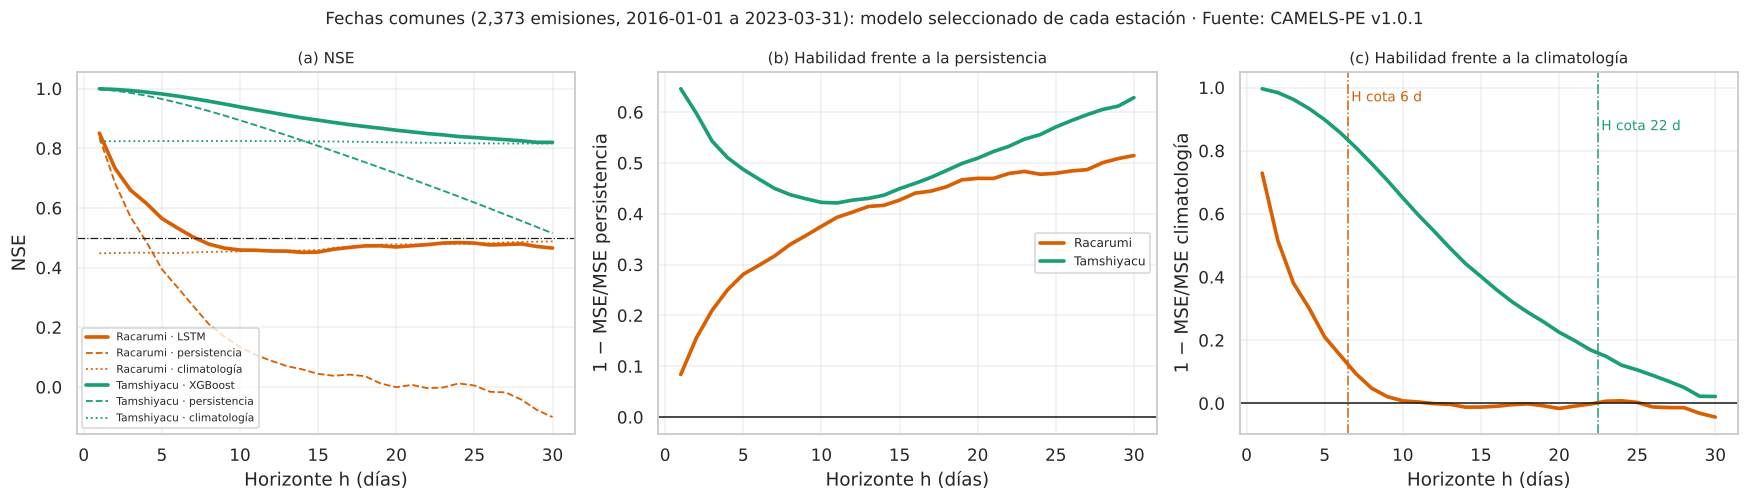

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for e in EST:
    mj = R[e]['mejor_modelo']
    t = T[e]['tabla_metricas_prueba_comun']; t = t[t['modelo'] == mj].set_index('h')
    rc = T[e]['tabla_referencias_prueba_comun']
    ax[0].plot(t.index, t['NSE'], color=COL_EST[e], lw=2.4, label=f'{e} · {mj}')
    ax[0].plot(rc.index, rc['NSE persistencia'], color=COL_EST[e], ls='--', lw=1.2, label=f'{e} · persistencia')
    ax[0].plot(rc.index, rc['NSE climatología'], color=COL_EST[e], ls=':', lw=1.2, label=f'{e} · climatología')
    ax[1].plot(t.index, t['hab_pers'], color=COL_EST[e], lw=2.4, label=e)
    ax[2].plot(t.index, t['hab_clim'], color=COL_EST[e], lw=2.4, label=e)
    hu = int(T[e]['tabla_horizonte_util_comun'].loc[mj, 'H cota 95 % (d)'])
    ax[2].axvline(min(hu, 30) + 0.5, color=COL_EST[e], ls='-.', lw=1)
    ax[2].text(min(hu, 29) + 0.7 if hu < 30 else 29.5, 0.92 if e == 'Racarumi' else 0.84, f'H cota {hu} d' if hu < 30 else 'H cota ≥ 30 d',
               color=COL_EST[e], ha='left' if hu < 30 else 'right', transform=ax[2].get_xaxis_transform(), fontsize=9)
ax[0].axhline(0.5, color='k', lw=0.8, ls='-.')
for a in ax[1:]:
    a.axhline(0, color='k', lw=1)
for a, ti, yl in zip(ax, ['(a) NSE', '(b) Habilidad frente a la persistencia', '(c) Habilidad frente a la climatología'],
                     ['NSE', '1 − MSE/MSE persistencia', '1 − MSE/MSE climatología']):
    a.set_title(ti, fontsize=10); a.set_xlabel('Horizonte h (días)'); a.set_ylabel(yl); a.grid(True, alpha=0.3)
ax[0].legend(fontsize=7, loc='lower left'); ax[1].legend(fontsize=8)
fc = R['Racarumi']['fechas_comunes']
fig.suptitle(f"Fechas comunes ({fc['n']:,} emisiones, {fc['inicio']} a {fc['fin']}): modelo seleccionado de cada estación · Fuente: CAMELS-PE v1.0.1", fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_horizonte_comparado.png', dpi=200, bbox_inches='tight'); plt.show()

In [5]:
FC = C.fechas_comunes()
REP, sel = {}, {}
for e in EST:
    z = Z[e]
    f = pd.to_datetime(z['fechas_pru'], unit='D')
    s = np.where(f.isin(FC))[0]
    nombres = [str(x) for x in z['modelos']]
    mj = R[e]['mejor_modelo']
    pr = z[f'pru_{nombres.index(mj)}'][s].astype(float)
    obs, pers, clim = (z[k][s].astype(float) for k in ('obs_pru', 'pers_pru', 'clim_pru'))
    assert (f[s] == FC).all()
    REP[e] = C.replicas_h(C.bootstrap_curvas(FC, obs, pr, pers, clim, B=2000, semilla=C.SEMILLA))
hr, ht = REP['Racarumi'], REP['Tamshiyacu']
dif = ht - hr
razon = np.where(hr > 0, ht / np.maximum(hr, 1), np.where(ht > 0, np.inf, 1.0))   # H_R = 0 y H_T > 0: razón infinita
filas = []
for e in EST:
    mj = R[e]['mejor_modelo']
    for periodo, k in [('fechas comunes', 'tabla_horizonte_util_comun'), ('prueba completa', 'tabla_horizonte_util')]:
        h = T[e][k].loc[mj]
        filas.append({'estación': e, 'periodo': periodo, 'modelo': mj, 'H cota 95 % (d)': int(h['H cota 95 % (d)']),
                      'H puntual (d)': int(h['H puntual (d)']), 'H p05–p95 (d)': f"{int(h['H p05 (d)'])}–{int(h['H p95 (d)'])}",
                      'NSE ≥ 0.5 hasta (d)': int(h['NSE ≥ 0.5 hasta (d)']),
                      'rango entre los 6 modelos, H cota (d)': f"{int(T[e][k].loc[MODELOS, 'H cota 95 % (d)'].min())}–{int(T[e][k].loc[MODELOS, 'H cota 95 % (d)'].max())}"})
h3 = pd.DataFrame(filas).set_index(['estación', 'periodo'])
h3.to_csv(RUTA_TAB / 'tabla_h3.csv')
par = pd.Series({'réplicas': len(dif), 'P(H Tamshiyacu > H Racarumi)': float(np.mean(dif > 0)),
                 'diferencia p05 (d)': float(np.quantile(dif, 0.05, method='inverted_cdf')),
                 'diferencia mediana (d)': float(np.median(dif)), 'diferencia p95 (d)': float(np.quantile(dif, 0.95, method='inverted_cdf')),
                 'P(razón ≥ 2)': float(np.mean(razon >= 2)), 'P(razón ≥ 5)': float(np.mean(razon >= 5)),
                 'razón p05 (cota inferior)': float(np.quantile(razon, 0.05, method='inverted_cdf')),
                 'P(H Tamshiyacu = 30, censurado)': float(np.mean(ht >= 30))}, name='bootstrap pareado (modelo seleccionado de cada estación)')
par.to_csv(RUTA_TAB / 'tabla_h3_pareado.csv')
display(h3)
par.round(3).to_frame()

modelo  H cota 95 % (d)  H puntual (d)  \
estación   periodo                                                    
Racarumi   fechas comunes      LSTM                6             11   
           prueba completa     LSTM                6             11   
Tamshiyacu fechas comunes   XGBoost               22             30   
           prueba completa  XGBoost               30             30   

                           H p05–p95 (d)  NSE ≥ 0.5 hasta (d)  \
estación   periodo                                              
Racarumi   fechas comunes           6–30                    7   
           prueba completa          6–30                    7   
Tamshiyacu fechas comunes          22–30                   30   
           prueba completa         30–30                   30   

                           rango entre los 6 modelos, H cota (d)  
estación   periodo                                                
Racarumi   fechas comunes                                    4–6  
           prueba completa                                   4–6  
Tamshiyacu fechas comunes                                  17–27  
           prueba completa                                 21–30

,bootstrap pareado (modelo seleccionado de cada estación)
réplicas,2000.000
P(H Tamshiyacu > H Racarumi),0.866
diferencia p05 (d),-1.000
diferencia mediana (d),17.000
diferencia p95 (d),24.000
P(razón ≥ 2),0.605
P(razón ≥ 5),0.094
razón p05 (cota inferior),0.966
"P(H Tamshiyacu = 30, censurado)",0.588


### 3.1 Sensibilidad de H3 al modelo de cada estación
El bootstrap pareado (las mismas 2 000 réplicas de meses) se repite con **cada combinación** de modelos de las dos estaciones: P(H Tamshiyacu > H Racarumi) y percentil 5 de la diferencia. **Es un análisis agregado después de ver el resultado principal:** no cambia el modelo seleccionado, solo muestra cuánto depende la conclusión de esa elección.

In [6]:
REP_M = {}
for e in EST:
    z = Z[e]
    f = pd.to_datetime(z['fechas_pru'], unit='D'); s = np.where(f.isin(FC))[0]
    nombres = [str(x) for x in z['modelos']]
    obs, pers, clim = (z[k][s].astype(float) for k in ('obs_pru', 'pers_pru', 'clim_pru'))
    REP_M[e] = {n: C.replicas_h(C.bootstrap_curvas(FC, obs, z[f'pru_{nombres.index(n)}'][s].astype(float), pers, clim, B=2000, semilla=C.SEMILLA))
                for n in MODELOS}
filas = []
for nr in MODELOS:
    for nt in MODELOS:
        d = REP_M['Tamshiyacu'][nt] - REP_M['Racarumi'][nr]
        filas.append({'modelo Racarumi': nr, 'modelo Tamshiyacu': nt, 'P(H T > H R)': float(np.mean(d > 0)),
                      'diferencia p05 (d)': float(np.quantile(d, 0.05, method='inverted_cdf')), 'diferencia mediana (d)': float(np.median(d)),
                      'H cota R (d)': float(np.percentile(REP_M['Racarumi'][nr], 5)), 'H cota T (d)': float(np.percentile(REP_M['Tamshiyacu'][nt], 5))})
h3s = pd.DataFrame(filas)
h3s.to_csv(RUTA_TAB / 'tabla_h3_sensibilidad_modelos.csv', index=False)
igual = h3s[h3s['modelo Racarumi'] == h3s['modelo Tamshiyacu']].set_index('modelo Racarumi')
print(f"P(H T > H R) en las 36 combinaciones: {h3s['P(H T > H R)'].min():.2f} a {h3s['P(H T > H R)'].max():.2f}")
display(igual[['P(H T > H R)', 'diferencia p05 (d)', 'diferencia mediana (d)']].round(2).rename_axis('mismo modelo en las dos'))
h3s.pivot(index='modelo Racarumi', columns='modelo Tamshiyacu', values='P(H T > H R)').round(2)

P(H T > H R) en las 36 combinaciones: 0.75 a 1.00


,P(H T > H R),diferencia p05 (d),diferencia mediana (d)
mismo modelo en las dos,,,
Regresión lineal,0.96,1.0,13.0
Random Forest,0.93,0.0,15.0
XGBoost,0.98,8.0,19.0
KNN,0.99,10.0,20.0
MLP,0.88,-2.0,14.0
LSTM,0.89,0.0,19.0


modelo Tamshiyacu,KNN,LSTM,MLP,Random Forest,Regresión lineal,XGBoost
modelo Racarumi,,,,,,
KNN,0.99,1.00,1.00,0.99,0.99,1.00
LSTM,0.84,0.89,0.83,0.83,0.75,0.87
MLP,0.89,0.93,0.88,0.88,0.81,0.90
Random Forest,0.94,0.97,0.93,0.93,0.87,0.95
Regresión lineal,0.97,0.98,0.98,0.97,0.96,0.98
XGBoost,0.98,0.98,0.98,0.98,0.96,0.98


**Interpretación — H3 se apoya en la cifra conservadora, pero no con 95 % de probabilidad para el par seleccionado:**
- **En las fechas comunes** (2 373 emisiones idénticas): H cota 95 % de **6 días** en Racarumi (LSTM) y **22 días** en Tamshiyacu (XGBoost); estimaciones puntuales de 11 y ≥ 30 días.
- **Bootstrap pareado** (las mismas 2 000 réplicas de meses): **P(H Tamshiyacu > H Racarumi) = 0.87**; la diferencia tiene mediana de 17 días y percentiles 5–95 de **−1** a 24 días. La razón es ≥ 2 con probabilidad 0.61 y ≥ 5 con 0.09.
- **Sensibilidad al modelo (sección 3.1, agregada después de ver este resultado):** en las 36 combinaciones de modelos P va de 0.75 a 1.00; con el mismo modelo en las dos estaciones, 0.88 (MLP), 0.89 (LSTM), 0.93 (Random Forest), 0.96 (regresión lineal), 0.98 (XGBoost) y 0.99 (KNN). En cambio, la **cota 95 %** es 4–6 días en Racarumi y 17–27 en Tamshiyacu con **cualquier** modelo.
- **De dónde viene la incertidumbre:** después de la primera semana la habilidad de Racarumi frente a la climatología queda cerca de cero; con los modelos flexibles, en algunas réplicas sigue apenas positiva y H llega a 30 días. Por eso la diferencia de H es incierta aunque los horizontes conservadores no se solapen.
- **Afirmación prudente:** con la cifra conservadora, el horizonte útil de Tamshiyacu (17–27 días) es claramente mayor que el de Racarumi (4–6 días) en estas fechas; la probabilidad de que el horizonte del par seleccionado sea mayor es 0.87; una razón fija (por ejemplo, «al menos 5 veces») no se sostiene.
- **Por qué (interpretación):** en Racarumi la persistencia pierde la mitad de su NSE en 3–4 días; en Tamshiyacu conserva NSE > 0.9 hasta los 10 días. Es coherente con la persistencia hidrológica medida en el EDA, pero con dos estaciones no se puede generalizar a cada vertiente ni atribuir la diferencia solo al tamaño de la cuenca.

---
## 4. Caída del desempeño y caudales elevados (H4)
> **H4.** El desempeño disminuye conforme aumenta el horizonte y los caudales elevados se representan peor que los ordinarios.

Con el modelo seleccionado de cada estación y en las **fechas comunes**: errores relativos y **absolutos** en días sobre el P95 frente a días ordinarios, sesgo y detección diaria (tabla de contingencia diaria); y errores **por evento** de toda la prueba (firmados: negativo = subestimación).

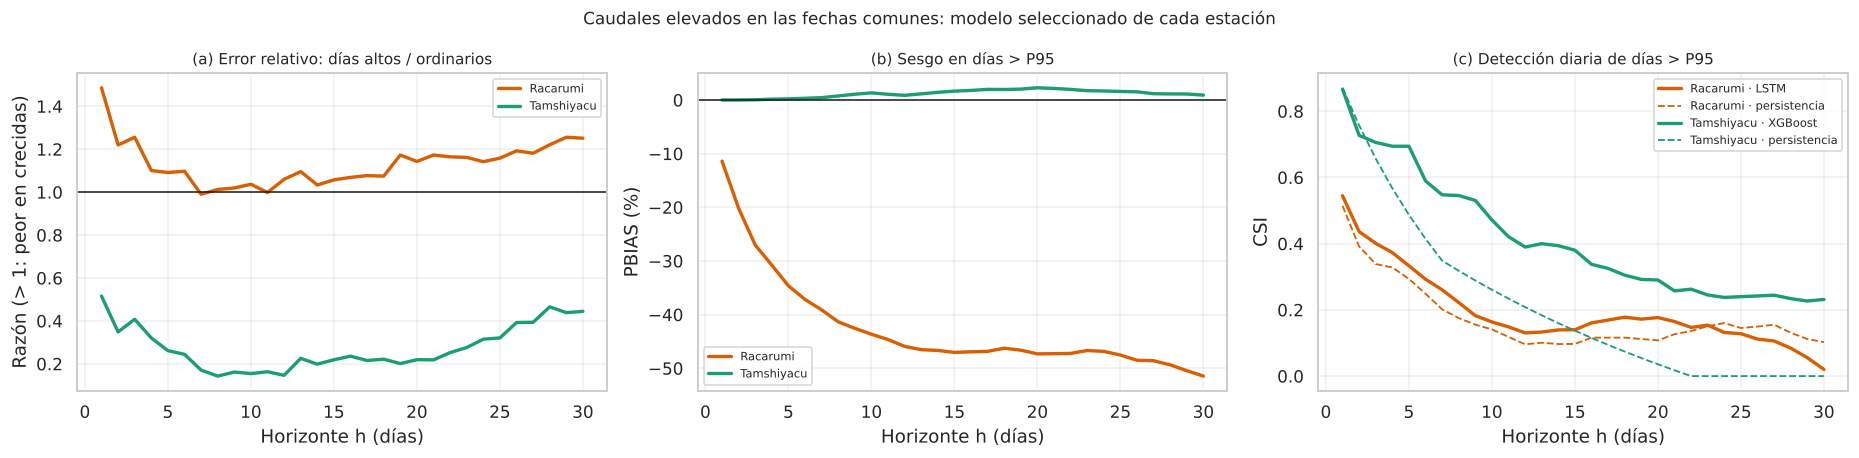

días altos  MAE días > P95 (m³/s)  MAE ordinarios (m³/s)  \
estación   h                                                              
Racarumi   1          131                  41.28                   5.56   
           3          134                  57.41                   9.97   
           7          143                  68.70                  13.10   
           15         140                  76.84                  14.43   
           30         138                  80.65                  14.14   
Tamshiyacu 1           29                 164.96                 196.01   
           3           29                 444.08                 660.80   
           7           29                 533.12                1545.74   
           15          29                 901.23                2802.81   
           30          29                2304.95                3738.99   

               MAE altos / P95 (%)  MAE altos persistencia (m³/s)  \
estación   h                                                        
Racarumi   1                 37.12                          43.70   
           3                 51.63                          64.15   
           7                 61.77                          78.34   
           15                69.09                          88.87   
           30                72.52                          98.85   
Tamshiyacu 1                  0.35                         151.65   
           3                  0.93                         328.01   
           7                  1.12                         594.84   
           15                 1.89                        1241.38   
           30                 4.84                        3359.64   

               error rel. altos (%)  error rel. ordinarios (%)  \
estación   h                                                     
Racarumi   1                  21.13                      14.22   
           3                  33.52                      26.69   
           7                  35.19                      35.53   
           15                 43.03                      40.69   
           30                 52.15                      41.67   
Tamshiyacu 1                   0.23                       0.45   
           3                   0.65                       1.60   
           7                   0.69                       4.05   
           15                  1.55                       7.07   
           30                  4.82                      10.84   

               PBIAS altos (%)  CSI diario  CSI persistencia  
estación   h                                                  
Racarumi   1            -11.39        0.54              0.51  
           3            -27.02        0.40              0.34  
           7            -39.11        0.26              0.20  
           15           -47.04        0.14              0.10  
           30           -51.46        0.02              0.10  
Tamshiyacu 1              0.01        0.87              0.87  
           3              0.05        0.71              0.66  
           7              0.44        0.55              0.35  
           15             1.66        0.38              0.14  
           30             0.92        0.23              0.00

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
filas = []
for e in EST:
    mj = R[e]['mejor_modelo']
    cr = T[e]['tabla_crecidas_prueba_comun']
    t, tp = cr[cr['modelo'] == mj].set_index('h'), cr[cr['modelo'] == 'Persistencia'].set_index('h')
    ax[0].plot(t.index, t['error_rel_altos'] / t['error_rel_ordinarios'], color=COL_EST[e], lw=2.2, label=e)
    ax[1].plot(t.index, t['PBIAS_altos'], color=COL_EST[e], lw=2.2, label=e)
    ax[2].plot(t.index, t['CSI'], color=COL_EST[e], lw=2.2, label=f'{e} · {mj}')
    ax[2].plot(tp.index, tp['CSI'], color=COL_EST[e], lw=1.2, ls='--', label=f'{e} · persistencia')
    for h in (1, 3, 7, 15, 30):
        filas.append({'estación': e, 'h': h, 'días altos': int(t.loc[h, 'n_altos']), 'MAE días > P95 (m³/s)': t.loc[h, 'MAE_altos'],
                      'MAE ordinarios (m³/s)': t.loc[h, 'MAE_ordinarios'], 'MAE altos / P95 (%)': 100 * t.loc[h, 'MAE_altos'] / R[e]['P95'],
                      'MAE altos persistencia (m³/s)': tp.loc[h, 'MAE_altos'],
                      'error rel. altos (%)': t.loc[h, 'error_rel_altos'], 'error rel. ordinarios (%)': t.loc[h, 'error_rel_ordinarios'],
                      'PBIAS altos (%)': t.loc[h, 'PBIAS_altos'], 'CSI diario': t.loc[h, 'CSI'], 'CSI persistencia': tp.loc[h, 'CSI']})
ax[0].axhline(1, color='k', lw=1); ax[1].axhline(0, color='k', lw=1)
for a, ti, yl in zip(ax, ['(a) Error relativo: días altos / ordinarios', '(b) Sesgo en días > P95', '(c) Detección diaria de días > P95'],
                     ['Razón (> 1: peor en crecidas)', 'PBIAS (%)', 'CSI']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.set_ylabel(yl); a.grid(True, alpha=0.3); a.legend(fontsize=7.5)
fig.suptitle('Caudales elevados en las fechas comunes: modelo seleccionado de cada estación', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_crecidas_comparadas.png', dpi=200, bbox_inches='tight'); plt.show()
h4 = pd.DataFrame(filas).set_index(['estación', 'h'])
h4.to_csv(RUTA_TAB / 'tabla_h4.csv')
h4.round(2)

In [8]:
ev_res = pd.concat({e: T[e]['tabla_eventos_resumen'] for e in EST}, names=['estación', 'h'])
ev_res.to_csv(RUTA_TAB / 'tabla_eventos_resumen.csv')
ev_res.round(1)

eventos con pronóstico  error firmado mediano (m³/s)  \
estación   h                                                         
Racarumi   1                      32                         -62.7   
           3                      32                         -78.7   
           7                      33                         -84.7   
Tamshiyacu 1                       3                        -219.3   
           3                       3                        -189.3   
           7                       3                        -110.7   

              error relativo firmado mediano (%)  \
estación   h                                       
Racarumi   1                               -42.9   
           3                               -54.3   
           7                               -52.6   
Tamshiyacu 1                                -0.4   
           3                                -0.4   
           7                                -0.2   

              eventos subestimados en el pico  \
estación   h                                    
Racarumi   1                               32   
           3                               32   
           7                               33   
Tamshiyacu 1                                2   
           3                                3   
           7                                2   

              error relativo mediano del máximo (%)  desfase p25 (d)  \
estación   h                                                           
Racarumi   1                                   -6.2              1.0   
           3                                  -19.0              3.0   
           7                                  -32.3              7.0   
Tamshiyacu 1                                    0.3              0.5   
           3                                    0.4              2.5   
           7                                    0.6              6.5   

              desfase mediano (d)  desfase p75 (d)  eventos con desfase = h  
estación   h                                                                 
Racarumi   1                  1.0              1.0                       33  
           3                  3.0              3.0                       33  
           7                  7.0              7.0                       27  
Tamshiyacu 1                  1.0              1.0                        2  
           3                  3.0              3.0                        2  
           7                  7.0              7.0                        2

**Interpretación — H4 se confirma en su primera parte y, en la segunda, solo en Racarumi y solo en términos relativos:**
- **"El desempeño cae con el horizonte":** se cumple en las dos estaciones (en las fechas comunes, NSE de 0.85 a 0.47 en Racarumi y de 0.999 a 0.82 en Tamshiyacu entre 1 y 30 días; CSI diario del P95 de 0.55 a 0.02 y de 0.87 a 0.23).
- **"Los caudales elevados se representan peor que los ordinarios":**
  - **Racarumi: sí.** Error relativo en días altos de 21 % frente a 14 % a 1 día; MAE de 41 frente a 6 m³/s; subestimación creciente (PBIAS −11 % a 1 día, −39 % a 7 días, −51 % a 30 días). En la prueba, el pronóstico para el día del pico queda por debajo en todos los eventos.
  - **Tamshiyacu: no en términos relativos** (0.23 % frente a 0.45 % a 1 día; 0.69 % frente a 4.0 % a 7 días), **pero sí es grande en m³/s** (533 m³/s a 7 días y 2 305 m³/s a 30 días en días altos). Solo 29 días altos en las fechas comunes y 3 eventos en toda la prueba: indicativo.
- **Detección diaria:** en Racarumi el modelo supera a la persistencia hasta los 15 días (CSI 0.26 frente a 0.20 a 7 días) pero no a 30 (0.02 frente a 0.10); en Tamshiyacu la supera desde los 3 días (0.55 frente a 0.35 a 7 días).

---
## 5. Estabilidad con varios orígenes
Horizonte útil (cota 95 %) en cada origen de los cuadernos 01–02, donde **toda** la preparación y la selección de hiperparámetros se hizo con el pasado de cada origen. Las comparaciones entre estaciones por origen usan las fechas de prueba de cada una (los vacíos difieren), así que son orientativas.

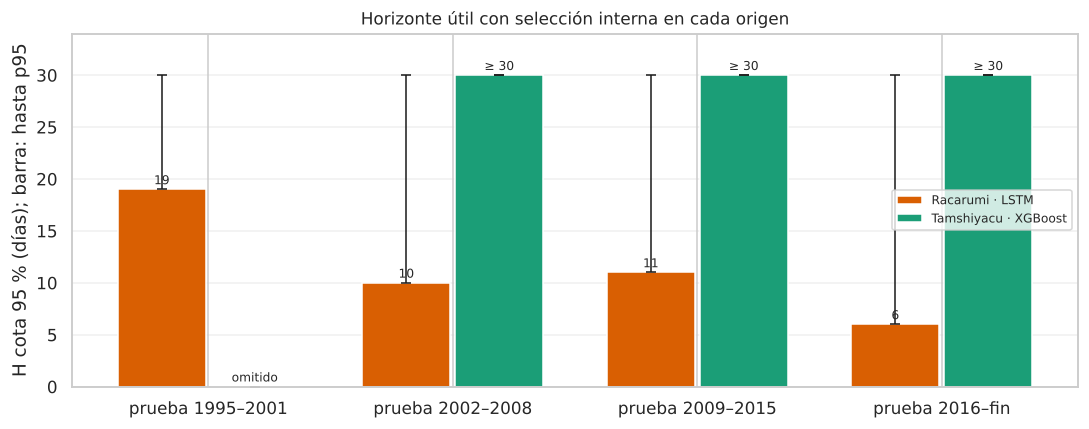

prueba                       1995–2001  2002–2008  2009–2015  2016–fin
estación   modelo                                                     
Racarumi   Regresión lineal       21.0        9.0        6.0       5.0
           XGBoost                13.0        7.0        6.0       5.0
           LSTM                   19.0       10.0       11.0       6.0
Tamshiyacu Regresión lineal        NaN       21.0       26.0      21.0
           XGBoost                 NaN       30.0       30.0      30.0
           LSTM                    NaN       30.0       30.0      30.0

In [9]:
filas = []
fig, ax = plt.subplots(figsize=(10, 4))
orden = ['1995–2001', '2002–2008', '2009–2015', '2016–fin']
for i, e in enumerate(EST):
    es = T[e]['tabla_estabilidad_temporal']
    s = es[es['modelo'] == R[e]['mejor_modelo']].set_index('prueba').reindex(orden)
    x = np.arange(len(orden)) + (i - 0.5) * 0.38
    ax.bar(x, s['H cota 95 % (d)'].fillna(0), width=0.36, color=COL_EST[e], label=f"{e} · {R[e]['mejor_modelo']}")
    ax.errorbar(x, s['H cota 95 % (d)'].fillna(0), yerr=[np.zeros(len(s)), (s['H p95 (d)'] - s['H cota 95 % (d)']).fillna(0)],
                fmt='none', ecolor='k', capsize=3, lw=1)
    for j, v in enumerate(s['H cota 95 % (d)']):
        ax.text(x[j], (0 if pd.isna(v) else v) + 0.5, 'omitido' if pd.isna(v) else ('≥ 30' if v >= 30 else str(int(v))), ha='center', fontsize=8)
    filas.append(es.assign(estación=e))
ax.set_xticks(range(len(orden))); ax.set_xticklabels([f'prueba {x}' for x in orden]); ax.set_ylim(0, 34)
ax.set_ylabel('H cota 95 % (días); barra: hasta p95'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3, axis='y')
ax.set_title('Horizonte útil con selección interna en cada origen', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig04_estabilidad.png', dpi=200, bbox_inches='tight'); plt.show()
estab = pd.concat(filas, ignore_index=True)
estab.to_csv(RUTA_TAB / 'tabla_estabilidad_comparada.csv', index=False)
pv = estab.pivot_table(index=['estación', 'modelo'], columns='prueba', values='H cota 95 % (d)', sort=False)
pv

**Interpretación:**
- **Tamshiyacu es estable:** H cota ≥ 30 días con XGBoost y la LSTM en los tres orígenes evaluables (1995–2001 se omite por falta de datos de entrenamiento); la regresión lineal, 21–26 días.
- **Racarumi varía mucho:** 19, 10, 11 y 6 días con la LSTM entre 1995–2001 y 2016–fin (regresión lineal 21, 9, 6 y 5); el periodo de prueba principal es el más difícil.
- **H3 en cada origen** (comparación orientativa, con las fechas de cada estación): Tamshiyacu ≥ 30 días frente a 10 (2002–2008), 11 (2009–2015) y 6 (2016–fin) en Racarumi con los modelos seleccionados.

---
## 6. Sensibilidad a la longitud de la historia y al calendario
Cuánto mejora el pronóstico (XGBoost, el mismo modelo auxiliar en las dos estaciones) con más días de historia (L) y qué se pierde sin calendario, a 1, 7 y 15 días.
**Cómo leerlo:** mide la **información predictiva** de los días antecedentes en este experimento; no es una medida de la memoria física del río.

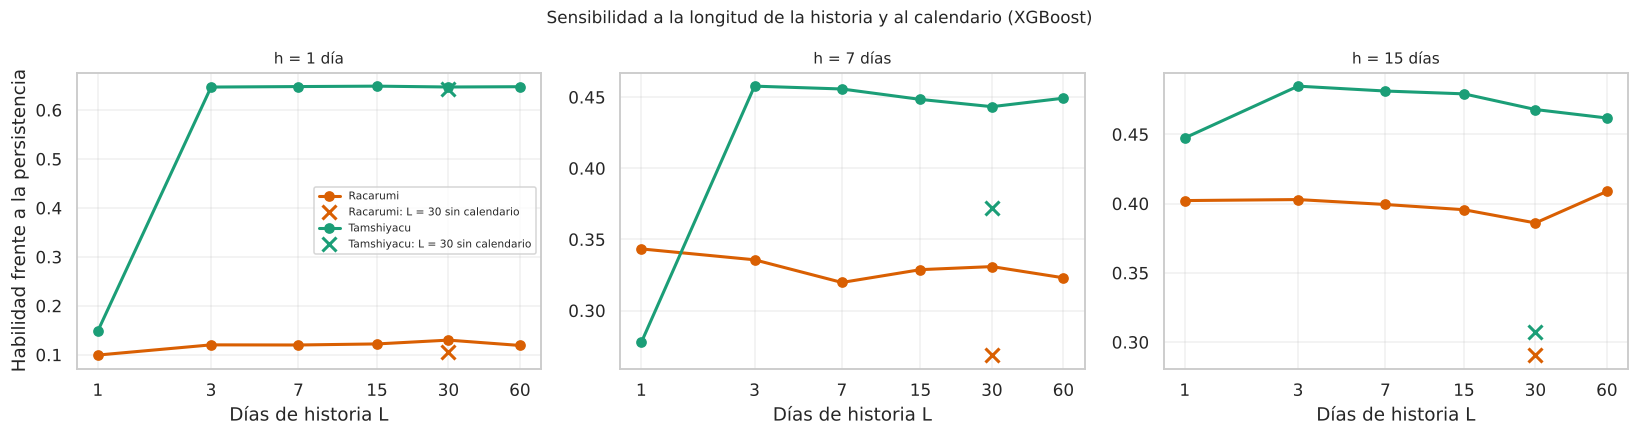

h                             hab. pers. h=1  hab. pers. h=7  hab. pers. h=15
estación   L                                                                 
Racarumi   1                           0.099           0.343            0.402
           3                           0.120           0.336            0.403
           7                           0.120           0.320            0.399
           15                          0.122           0.329            0.396
           30                          0.130           0.331            0.386
           60                          0.119           0.323            0.409
           30 sin calendario           0.106           0.269            0.291
Tamshiyacu 1                           0.148           0.278            0.447
           3                           0.647           0.458            0.485
           7                           0.648           0.456            0.481
           15                          0.649           0.448            0.479
           30                          0.647           0.443            0.468
           60                          0.648           0.449            0.462
           30 sin calendario           0.643           0.372            0.307

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
filas = []
for a, h in zip(ax, (1, 7, 15)):
    for e in EST:
        t = T[e]['tabla_memoria']; t = t[t['h'] == h].set_index('L')
        num = t.loc[[x for x in t.index if 'sin' not in str(x)]]
        xs = [int(x) for x in num.index]
        a.plot(xs, num['hab_pers'], 'o-', color=COL_EST[e], lw=2, label=e)
        sc = t.loc[[x for x in t.index if 'sin' in str(x)]]
        a.plot([30] * len(sc), sc['hab_pers'], 'x', color=COL_EST[e], ms=9, mew=2, label=f'{e}: L = 30 sin calendario')
        for Lm in t.index:
            filas.append({'estación': e, 'h': h, 'L': str(Lm), 'hab_pers': t.loc[Lm, 'hab_pers'], 'NSE': t.loc[Lm, 'NSE']})
    a.set_xscale('log'); a.set_xticks([1, 3, 7, 15, 30, 60]); a.set_xticklabels([1, 3, 7, 15, 30, 60])
    a.set_xlabel('Días de historia L'); a.set_title(f"h = {h} {'día' if h == 1 else 'días'}", fontsize=10); a.grid(True, alpha=0.3)
ax[0].set_ylabel('Habilidad frente a la persistencia'); ax[0].legend(fontsize=7)
fig.suptitle(f'Sensibilidad a la longitud de la historia y al calendario ({C.BASE_AUX})', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_memoria_comparada.png', dpi=200, bbox_inches='tight'); plt.show()
mem = pd.DataFrame(filas).pivot_table(index=['estación', 'L'], columns='h', values='hab_pers', sort=False).add_prefix('hab. pers. h=')
mem.to_csv(RUTA_TAB / 'tabla_memoria_comparada.csv')
mem.round(3)

**Interpretación — la información útil está en el estado actual del río y en la época del año (XGBoost en las dos estaciones):**
- **Racarumi:** con L = 1 (caudal de hoy y fecha) ya alcanza su habilidad; más historia cambia ≤ 0.03.
- **Tamshiyacu:** pasar de L = 1 a L = 3 multiplica por 4 la habilidad a 1 día (0.15 → 0.65); lo que aporta es la **tendencia**, que en el Amazonas se mantiene por semanas. Más de 3–7 días no mejora.
- **Calendario:** sin él, la habilidad a 15 días cae de 0.39 a 0.29 en Racarumi y de 0.47 a 0.31 en Tamshiyacu. A horizontes largos el calendario es una parte grande de la información aprovechable en ambas.
- **Cómo leerlo:** mide la información predictiva de los caudales antecedentes en este experimento; no es una medida de la memoria física de la cuenca.

In [11]:
imp = pd.concat({e: T[e]['tabla_importancia'] * 100 for e in EST}, names=['estación', 'grupo'])
imp.to_csv(RUTA_TAB / 'tabla_importancia_comparada.csv')
imp.round(1)

h=1    h=3    h=7   h=15    h=30
estación   grupo                                                             
Racarumi   Caudal de hoy (nivel)            19.8   70.2  318.4  685.5  2917.6
           Cambio en los últimos 1–3 días    4.7    1.6    0.3    1.0     0.3
           Días 4–7                          2.8    1.0    2.8    5.3     0.4
           Días 8–15                         5.8    7.6    7.6    5.6     3.5
           Días 16–30                        2.5    5.6    6.4    4.5     8.7
           Época del año                     6.7   12.2   19.6   38.1    94.2
Tamshiyacu Caudal de hoy (nivel)             3.4   17.6   44.5  116.6   288.2
           Cambio en los últimos 1–3 días  594.8  342.9  141.7   33.3     5.5
           Días 4–7                          6.3    6.5    1.1   -0.1     0.1
           Días 8–15                         0.0    0.4    1.5    1.1     0.8
           Días 16–30                        0.7    1.4    2.1    4.8     4.5
           Época del año                     4.2   18.5   51.8  139.8   315.1

**Interpretación (XGBoost):**
- **Racarumi:** el nivel de hoy es lo más usado en todos los horizontes y la época del año gana peso con el horizonte; la tendencia de los últimos días casi no se usa (≤ 5 %).
- **Tamshiyacu:** la tendencia de los últimos 1–3 días es lo más usado hasta los 7 días (+595 % de error sin ella a 1 día); después, el nivel y la época del año.
- En las dos, la historia de 4 a 30 días aporta ≤ 9 %. Describe el uso del modelo, no causas.

---
## 7. Selección del modelo y conclusiones (3.5–3.6)

**Regla fijada antes de evaluar:** mayor NSE medio en el bloque de selección (2012–2015, corrección de retransformación estimada en 2009–2011); diferencias pareadas con IC 90 %; equivalente si el IC cabe en ±0.01; se elige el más simple entre el mejor y sus equivalentes. La prueba no decide.

| | Racarumi (Chancay-Lambayeque, Pacífico) | Tamshiyacu (Amazonas) |
|---|---|---|
| Modelo seleccionado | **LSTM** (0.560); regresión lineal, MLP, Random Forest y KNN **inconclusos**; XGBoost peor | **XGBoost** (0.935); Random Forest y KNN **inconclusos**; MLP, LSTM y regresión lineal peores |
| Horizonte útil, H cota 95 % (fechas comunes) | **6 días** (todos los modelos: 4–6) | **22 días** (todos: 17–27) |
| Horizonte útil, H cota 95 % (prueba completa) | 6 días | ≥ 30 días |
| Otros orígenes | 10–19 días | ≥ 30 días |
| Calidad (NSE ≥ 0.5) | hasta 5–7 días | ≥ 30 días |
| Caudales altos | peor que días ordinarios; subestimación de −11 % a −51 % | error relativo ≤ 1 % hasta 15 días, pero 500–900 m³/s a 7–15 días |
| Información que usa | nivel de hoy + época del año | tendencia de 1–3 días + nivel + época |

**Justificación y matices:**
1. **Ningún modelo domina en las dos estaciones**, y en ninguna el seleccionado tiene una ventaja demostrada: sus diferencias con varios candidatos son inconclusas.
2. **En Racarumi** la regresión lineal (0.007 menos de NSE de selección, 1 día menos de cota) es una alternativa práctica más simple y estable que la LSTM, sin afirmar que sean iguales. **En Tamshiyacu** los no lineales superan a la regresión lineal (0.03 de NSE de selección, 3–10 días de H cota en las fechas comunes); Random Forest y KNN son alternativas sin diferencia demostrada con XGBoost.
3. **Las diferencias entre los mejores de cada estación son del orden de la variación entre semillas de las redes.**
4. **Para avisar cruces nuevos del P95 el modelo puede ser otro** (cuaderno 04).

**Hipótesis:** **H3 se apoya en la cifra conservadora** (cota 95 % de 4–6 días frente a 17–27 días con cualquier modelo), pero la probabilidad de que el horizonte del par seleccionado sea mayor en Tamshiyacu es 0.87, por debajo de 0.95; "al menos 5 veces" no se sostiene. **H4 se confirma en su primera parte** en ambas estaciones **y en la segunda solo en Racarumi**; en Tamshiyacu el error de las crecidas es relativamente pequeño pero grande en m³/s.

---
## 8. Limitaciones
- **Prueba ya consultada:** el periodo 2016–fin se consultó durante el desarrollo del proyecto. El protocolo se congeló antes de la evaluación final, pero qué modelos conservar y la regla de «el más simple entre equivalentes» se decidieron después de ver resultados previos; la sensibilidad de H3 al modelo (sección 3.1) se agregó después de ver el resultado principal.
- **Bloque de selección de 4 años:** con 1 195–1 369 emisiones, muchas diferencias entre modelos quedan inconclusas; un bloque más largo reduciría la incertidumbre.
- **Solo caudal antecedente y calendario:** sin lluvia ni pronósticos de lluvia. Este diseño no puede medir cuánto mejoraría el pronóstico con ellos.
- **Dos estaciones:** las diferencias se refieren a Racarumi y Tamshiyacu y a estos periodos; no se generalizan a todas las cuencas del Pacífico o de la Amazonía.
- **Pocas crecidas en Tamshiyacu:** 3 eventos en la prueba (29 días altos en las fechas comunes); sus métricas de crecida son indicativas.
- **Horizonte censurado en 30 días:** en Tamshiyacu el límite no se encontró; las razones entre estaciones son cotas inferiores.
- **Escalones de nivel de Tamshiyacu (1985–2014):** se excluyen las ventanas que los cruzan; la escala de los bloques anteriores a 2015 debería confirmarse con SENAMHI.
- **Fechas comunes hasta 2023-03:** Racarumi termina el 2023-08-31 en CAMELS-PE y Tamshiyacu tiene vacíos en 2023; la comparación excluye 2023-04 a 2025.
- **Umbral P95 estadístico:** no es un umbral oficial de alerta.
- **Configuraciones ajustadas por modelo:** mallas predefinidas de 1 a 40 combinaciones y ventanas distintas (KNN elige 3–30 días); una búsqueda más amplia podría cambiar el orden entre modelos con diferencias pequeñas.
- **Bootstrap por bloques de meses:** los objetivos de emisiones vecinas se solapan hasta 30 días; la sensibilidad a bloques de 15 días y 3 meses no cambió las cotas del modelo seleccionado en más de 1 día.